[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/eirasf/GCED-AA2/blob/main/es/lab7/lab7.ipynb)
# Práctica 7: Residual neural networks


### Pre-requisitos. Instalar paquetes

Para la primera parte de este Laboratorio 8 necesitaremos torch. Además, como habitualmente, fijaremos la semilla aleatoria para asegurar la reproducibilidad de los experimentos.

In [1]:
import torch
import pandas as pd
import seaborn as sns
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#Fijamos la semilla para poder reproducir los resultados
import os
import numpy as np
import random
seed=1234
os.environ['PYTHONHASHSEED']=str(seed)
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

### Carga del conjunto de datos

De nuevo, seguimos empleando el conjunto *Titanic* ya empleado en los laboratorios anteriores.


In [2]:
# TODO - Carga el conjunto Titanic. No es necesario hacer particiones, pero asegúrate de que las
# variables estén en la escala apropiada
def load_titanic_raw():
    # 1. Cargamos el dataset Titanic desde seaborn
    df = sns.load_dataset('titanic')

    # Selección de variables relevantes y limpieza
    cols = ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'alone']
    df = df[cols].copy()

    # Eliminamos filas con valores faltantes
    df = df.dropna(subset=['age', 'embarked', 'fare'])

    # 2. Separar etiquetas y características
    y = df['survived'].to_numpy().astype(np.float32)
    X = df.drop(columns=['survived'])

    # 3. One-hot encoding para variables categóricas
    categorical_cols = ['pclass', 'sex', 'embarked', 'alone', 'sibsp', 'parch']
    X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

    # Convertimos a float32 para PyTorch
    X_np = X_encoded.to_numpy().astype(np.float32)
    y_np = y.reshape(-1, 1).astype(np.float32)

    # Identificamos las columnas numéricas ('age' y 'fare') por sus índices para el escalado
    numeric_indices = [X_encoded.columns.get_loc('age'), X_encoded.columns.get_loc('fare')]

    return X_np, y_np, numeric_indices

# --- Carga de datos raw ---
X, y, numeric_indices = load_titanic_raw()

# --- TODO - Carga y Escalado del conjunto Titanic (sin particiones) ---
scaler = StandardScaler()
X[:, numeric_indices] = scaler.fit_transform(X[:, numeric_indices])

# --- Conversión a Tensores de PyTorch ---
X_tensor = torch.from_numpy(X)
y_tensor = torch.from_numpy(y)

# --- Encapsulado en un Dataset y DataLoader único ---
batch_size = 32
dataset = TensorDataset(X_tensor, y_tensor)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

print(f"Muestras totales cargadas y escaladas: {len(X)}")

Muestras totales cargadas y escaladas: 712


## Visualización del desvanecimiento del gradiente
Las Residual neural networks se ocupan de que los gradientes no se desvanezcan cuando la red es muy profunda. Vamos a visualizar este problema creando una red profunda y mostrando las dimensiones de los gradientes que llegan a cada capa.

### Creamos un modelo *Sequential*
Creamos un modelo *Sequential* para ajustar a los datos de entrada siguiendo las especificaciones dadas.

In [3]:
# TODO - Define en model una red MLP con 20 capas ocultas, con activación sigmoide, con 10 unidades por capa.
class MLP(nn.Module):
    def __init__(self, input_dim, output_dim, num_hidden_layers=20, hidden_units=10, activation=nn.Sigmoid()):
        super(MLP, self).__init__()

        layers = []

        # 1. Primera capa oculta (conecta la entrada con la primera capa oculta)
        layers.append(nn.Linear(input_dim, hidden_units))
        layers.append(activation)

        # 2. Capas ocultas intermedias (num_hidden_layers - 1 capas adicionales)
        for _ in range(num_hidden_layers - 1):
            layers.append(nn.Linear(hidden_units, hidden_units))
            layers.append(activation)

        # 3. Capa de salida
        layers.append(nn.Linear(hidden_units, output_dim))

        # Agrupamos todo en un Sequential
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

### Entrenamiento del modelo
Entrena el modelo durante 10 epochs. En el bucle de entrenamiento, guarda en un diccionario con el formato mostrado el histórico de gradientes de cada capa.

In [4]:
# TODO - Entrena el modelo durante 10 epochs
# Cambia tu train step guardar los gradientes en un diccionario con este formato:
# g_hist = {name: [] for name, param in model.named_parameters() if 'weight' in name}
# Por cada parámetro que se llame weight (ignoraremos los bias en este ejercicio),
# guardaremos una lista con un valor por cada epoch. En la lista de cada parámetro,
# debes guardar la media de las normas de los gradientes de ese parámetro durante
# los pasos de cada epoch.
# Para calcular la norma del gradiente de un parámetro puedes usar:
# torch.norm(param.grad.detach()))

# --- 0. Asegurarnos de que el modelo esté creado ---
input_dim = X.shape[1]
output_dim = 1

model = MLP(
    input_dim=input_dim,
    output_dim=output_dim,
    num_hidden_layers=20,
    hidden_units=10,
    activation=nn.Sigmoid()
)

# --- 1. Definimos la función de pérdida y el optimizador ---
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

# --- 2. Inicializamos el diccionario para el histórico de gradientes ---
g_hist = {name: [] for name, param in model.named_parameters() if 'weight' in name}

# --- 3. Bucle de entrenamiento ---
epochs = 10
model.train()

for epoch in range(epochs):
    epoch_grad_sums = {name: 0.0 for name in g_hist.keys()}
    num_batches = 0

    for batch_X, batch_y in dataloader:
        optimizer.zero_grad()

        # Forward pass
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)

        # Backward pass
        loss.backward()

        # Acumulamos la norma del gradiente de cada peso
        for name, param in model.named_parameters():
            if 'weight' in name and param.grad is not None:
                grad_norm = torch.norm(param.grad.detach()).item()
                epoch_grad_sums[name] += grad_norm

        optimizer.step()
        num_batches += 1

    # Al finalizar la época, calculamos la media de las normas y la guardamos
    for name in g_hist.keys():
        mean_grad_norm = epoch_grad_sums[name] / num_batches if num_batches > 0 else 0.0
        g_hist[name].append(mean_grad_norm)

    print(f"Época [{epoch+1}/{epochs}] - Loss: {loss.item():.4f}")
# --- Mostrar el historial de gradientes por capa y época ---
print("\n--- Historial de Gradientes (Norma media por época) ---")
for name, norms in g_hist.items():
  # Formateamos los valores a 6 decimales para que se lean mejor
    formatted_norms = [f"{val:.6f}" for val in norms]
    print(f"{name}: {formatted_norms}")


Época [1/10] - Loss: 0.7034
Época [2/10] - Loss: 0.6252
Época [3/10] - Loss: 0.7005
Época [4/10] - Loss: 0.5969
Época [5/10] - Loss: 0.7660
Época [6/10] - Loss: 0.6701
Época [7/10] - Loss: 0.7433
Época [8/10] - Loss: 0.6663
Época [9/10] - Loss: 0.6629
Época [10/10] - Loss: 0.6153

--- Historial de Gradientes (Norma media por época) ---
model.0.weight: ['0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000']
model.2.weight: ['0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000']
model.4.weight: ['0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000']
model.6.weight: ['0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000']
model.8.weight: ['0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '0.000000', '

Ahora que hemos hecho algunos pasos de entrenamiento, representamos el tamaño
medio de los pesos de cada capa.

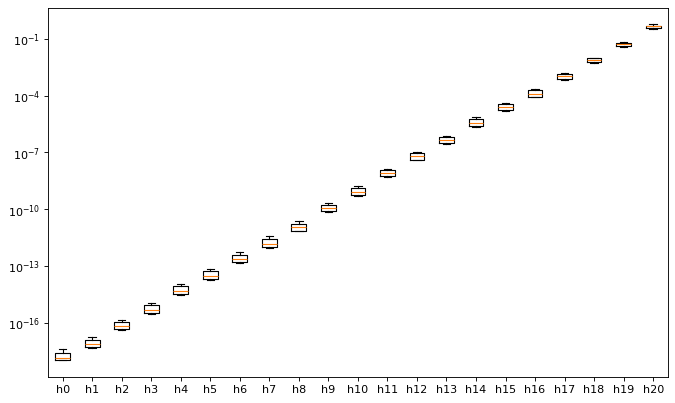

In [8]:
from matplotlib import pyplot as plt
# Ahora accedemos al historial de gradientes y representamos el tamaño medio de los gradientes de cada capa.
plt.figure(figsize=(10, 6), dpi=80)
plt.boxplot(g_hist.values())
plt.yscale('log')
plt.xticks(ticks=range(1,len(g_hist)+1), labels=[f'h{int(k.split('.')[1])//2}' for k in g_hist.keys()])
plt.show()

## Comparativa
 - ¿Qué observas en los pesos?
 - ¿Ocurre lo mismo utilizando ReLU como función de activación de las capas ocultas?
 - Repite la prueba con las distintas [funciones de activación](https://docs.pytorch.org/docs/stable/nn.html#non-linear-activations-weighted-sum-nonlinearity) que tengan sentido.
 - Prueba a utilizar He initialization para tus capas Dense (ver código en la celda siguiente)
 - (OPCIONAL) Alarga el entrenamiento y prueba distintos optimizadores para intentar que el modelo entrene correctamente.

1. Desvanecimineto del gradiente. Las capas más profundas (las más cercanas a la entrada). Esto se debe a que muestran gradientes con órdenes de magnitud drásticamente más pequeños (cercanos a $0$) en comparación con las últimas capas (h19)

2. NO, la función ReLU tiene una derivada de $1$ para cualquier entrada positiva ($x > 0$). Por lo tanto, al aplicar la regla de la cadena, los gradientes no se multiplican por un factor menor que 1 de forma constante, lo que evita el desvanecimiento severo del gradiente y permite que las redes profundas aprendan con mucha más eficiencia.

3.  
- nn.Tanh(): Mitiga ligeramente el problema en comparación con la sigmoide (su derivada máxima es $1$ en el origen), pero aún puede sufrir de desvanecimiento en redes muy profundas de 20 capas debido a que satura en los extremos (-1 y 1).
  
- nn.LeakyReLU(): Una variante de ReLU que evita las neuronas muertas al permitir un pequeño gradiente cuando la entrada es negativa. Funciona excelente para evitar el desvanecimiento.


In [6]:
# Ejemplo de He initialization
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, input_dim, output_dim, num_hidden_layers=20, hidden_units=10, activation=nn.ReLU()):
        super(MLP, self).__init__()

        layers = []

        # 1. Primera capa oculta
        layers.append(nn.Linear(input_dim, hidden_units))
        layers.append(activation)

        # 2. Capas ocultas intermedias
        for _ in range(num_hidden_layers - 1):
            layers.append(nn.Linear(hidden_units, hidden_units))
            layers.append(activation)

        # 3. Capa de salida (lineal)
        layers.append(nn.Linear(hidden_units, output_dim))

        # Agrupamos todo en el modelo secuencial
        self.model = nn.Sequential(*layers)

        # --- APLICACIÓN DE HE INITIALIZATION (Dentro de la clase, usando self.model) ---
        for layer in self.model:
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_uniform_(layer.weight, nonlinearity='relu')
                if layer.bias is not None:
                    nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.model(x)

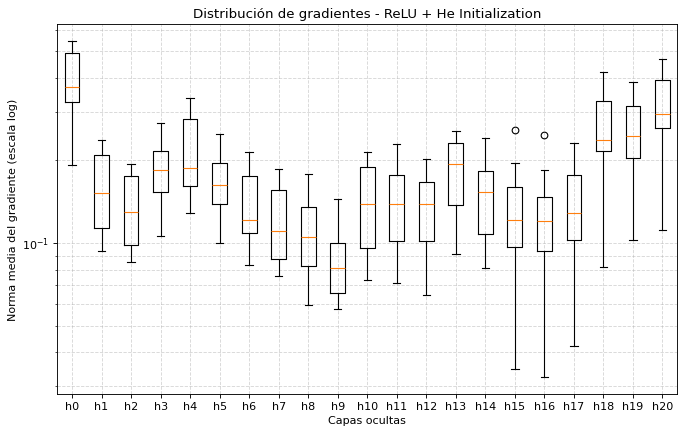

In [13]:
# Abajo se muestra el resultado con ReLU y He initialization


---
# Parte 2

### Creación del bloque con conexión residual

En una red neuronal *feed-forward* convencional, la salida de cada capa se utiliza como entrada de las capa siguiente.

<img src="https://github.com/eirasf/GCED-AA2/blob/main/es/lab7/img/resnet.png?raw=1" alt="Dos capas en una red FF" width="400"/>

En contraste, en una ResNet se introducen bloques que incluyen conexiones residuales con el objetivo de favorecer la propagación de los gradientes.

<img src="https://github.com/eirasf/GCED-AA2/blob/main/es/lab7/img/resnet-2.png?raw=1" alt="Dos capas en una red FF con conexión residual" width="400"/>

A pesar de que las ResNet se suelen utilizar con redes convolucionales, en este Laboratorio utilizaremos una red *feed-forward*.

Para poder utilizar este tipo de bloques en nuestra arquitectura definiremos un nuevo tipo de modelo denominado `BlockWithSkipConnection` que consistirá en lo representado en la imagen:
 - Una primera capa con activación, cuya salida sirve de entrada a...
 - Una segunda capa lineal (sin activación), cuya salida sirve de entrada a...
 - A una operación suma que la añade a la entrada original a la primera capa. La salida de esta suma servirá de entrada a...
 - Una función de activación, cuya salida será la salida del bloque.

Utilizaremos la función sigmoide como función de activación en ambos casos. La entrada y la salida del bloque deberán tener la misma dimensión para que se pueda realizar la suma. Por simplicidad, mantendremos la salida de la primera capa con la misma dimensión.

In [7]:
class BlockWithSkipConnection(nn.Module):
    def __init__(self, dim, outer_activation=nn.Sigmoid(), inner_activation=nn.Sigmoid()):
        super(BlockWithSkipConnection, self).__init__()

        # 1. Primera capa lineal y su activación interna
        self.linear1 = nn.Linear(dim, dim)
        self.inner_activation = inner_activation

        # 2. Segunda capa lineal (sin activación propia)
        self.linear2 = nn.Linear(dim, dim)

        # 3. Activación final del bloque (outer activation)
        self.outer_activation = outer_activation

    def forward(self, x):
        # Guardamos la entrada original para la conexión residual (skip connection)
        residual = x

        # Primera capa con activación
        out = self.linear1(x)
        out = self.inner_activation(out)

        # Segunda capa lineal (sin activación)
        out = self.linear2(out)

        # Operación suma: añadimos la entrada original (residual)
        out = out + residual

        # Función de activación final del bloque
        out = self.outer_activation(out)

        return out

## Creamos un modelo utilizando los nuevos bloques
Creamos un modelo *MLPWithSkipConnections* para ajustar a los datos de entrada siguiendo las especificaciones dadas. Deberá incluir una capa de entrada de 10 unidades con activación sigmoide, 10 de los nuevos bloques y la capa de salida apropiada.

In [8]:
class MLPWithSkipConnections(nn.Module):
    def __init__(self, input_dim, output_dim, num_blocks=10, hidden_units=10, activation=nn.Sigmoid()):
        super(MLPWithSkipConnections, self).__init__()

        # 1. Capa de entrada: transforma input_dim a hidden_units con su activación
        self.input_linear = nn.Linear(input_dim, hidden_units)
        self.activation = activation

        # 2. Bloques con conexiones residuales (10 bloques por defecto)
        self.blocks = nn.ModuleList([
            BlockWithSkipConnection(
                dim=hidden_units,
                outer_activation=activation,
                inner_activation=activation
            )
            for _ in range(num_blocks)
        ])

        # 3. Capa de salida: mapea de hidden_units a output_dim
        self.output_linear = nn.Linear(hidden_units, output_dim)

    def forward(self, x):
        # Paso por la capa de entrada y su activación
        x = self.input_linear(x)
        x = self.activation(x)

        # Propagación a través de cada uno de los bloques residuales secuencialmente
        for block in self.blocks:
            x = block(x)

        # Capa de salida final
        x = self.output_linear(x)

        return x

Época [1/10] - Loss: 0.5883
Época [2/10] - Loss: 0.8155
Época [3/10] - Loss: 0.7808
Época [4/10] - Loss: 0.7327
Época [5/10] - Loss: 0.6618
Época [6/10] - Loss: 0.6966
Época [7/10] - Loss: 0.4811
Época [8/10] - Loss: 0.6647
Época [9/10] - Loss: 0.6076
Época [10/10] - Loss: 0.6643


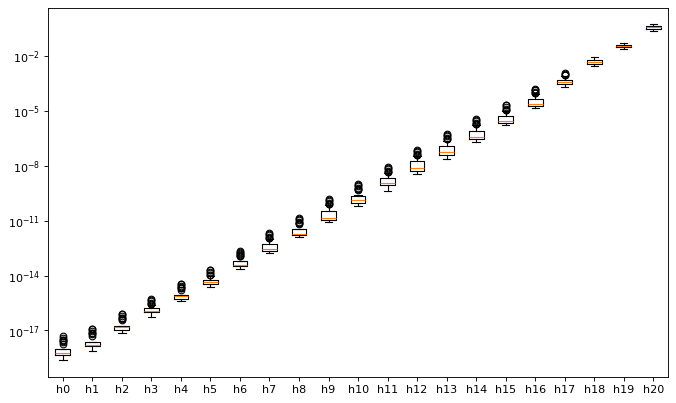

In [10]:
from matplotlib import pyplot as plt
# --- Bucle de entrenamiento y almacenamiento de gradientes ---
epochs = 10
model.train()

for epoch in range(epochs):
    epoch_grad_sums = {name: 0.0 for name in g_hist.keys()}
    num_batches = 0

    for batch_X, batch_y in dataloader:
        optimizer.zero_grad()

        # Forward pass
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)

        # Backward pass
        loss.backward()

        # Acumulamos la norma del gradiente de cada peso
        for name, param in model.named_parameters():
            if 'weight' in name and param.grad is not None:
                grad_norm = torch.norm(param.grad.detach()).item()
                epoch_grad_sums[name] += grad_norm

        optimizer.step()
        num_batches += 1

    # Al finalizar la época, calculamos la media de las normas y la guardamos
    for name in g_hist.keys():
        mean_grad_norm = epoch_grad_sums[name] / num_batches if num_batches > 0 else 0.0
        g_hist[name].append(mean_grad_norm)

    print(f"Época [{epoch+1}/{epochs}] - Loss: {loss.item():.4f}")

# --- Visualización del historial de gradientes ---
# Ahora accedemos al historial de gradientes y representamos el tamaño medio de los gradientes de cada capa.
plt.figure(figsize=(10, 6), dpi=80)
plt.boxplot(g_hist.values())
plt.yscale('log')
plt.xticks(ticks=range(1,len(g_hist)+1), labels=[f'h{int(k.split(".")[1])//2}' for k in g_hist.keys()])
plt.show()

## Comparativa
 - Contrasta los resultados con los obtenidos en la primera parte
 - Cambia las activaciones del exteriores del bloque y de la primera capa oculta de la red a ReLU y observa la diferencia.
 - Alarga el entrenamiento y prueba distintos optimizadores para intentar que el modelo entrene correctamente.

1.
* Red MLP Estándar de 20 capas (con Sigmoide): Al entrenar esta red en la primera parte, observaste en el boxplot que las capas iniciales (cercanas a la entrada) sufrían un desvanecimiento severo del gradiente (normas cercanas a cero). Las activaciones sigmoides comprimen los gradientes, haciendo que las primeras capas prácticamente no aprendieran.

* Red con Skip Connections (con Sigmoide): Al introducir los bloques residuales, las conexiones de identidad permiten que el gradiente viaje directamente hacia atrás sin ser atenuado por las funciones no lineales. Como resultado, las normas de los gradientes en las capas iniciales se mantienen saludables y comparables a las de las capas finales, incluso usando activaciones sigmoides.


2.

Propagación del gradiente aún más fuerte: ReLU no sufre de saturación en valores positivos, por lo que los gradientes fluyen de forma muy eficiente.

Combinación de ReLU + Skip Connections:Al combinar ReLU profundo con conexiones residuales, prestar atención a que los gradientes no crezcan demasiado (exploding gradients).

